# Лабораторная работа №2: классификация

**Задача:** пройти полный цикл классификации на Titanic: исследовать данные, построить baseline, сравнить Decision Tree, Random Forest, Gradient Boosting, SVC и KNN, проанализировать важность признаков и ошибки выбранной модели.

Целевая переменная — `Survived`: 1 — пассажир выжил, 0 — погиб. Основная метрика — **F1-score для класса 1**. Требуемый уровень для пяти основных моделей — **F1 > 0.70**.

Источник данных: [Kaggle — Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset). В наборе 891 пассажир, 11 исходных признаков и целевая переменная.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, make_scorer, precision_score, recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

RANDOM_STATE = 42
TEST_SIZE = 0.2
print(f"random_state={RANDOM_STATE}, test_size={TEST_SIZE:.0%}")

random_state=42, test_size=20%


## 1. Загрузка и первичная проверка данных

Считаем датасет и посмотрим на его строки, типы признаков и пропуски.

In [2]:
PATH = Path("data/Titanic-Dataset.csv")
if not PATH.exists():
    raise FileNotFoundError("Нужен Titanic-Dataset.csv с указанной страницы Kaggle в папке data/.")
df = pd.read_csv(PATH)

print("Размер исходных данных:", df.shape)
display(df.head())

Размер исходных данных: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [3]:
quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
display(quality_report)
print("Полных дубликатов:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,unique
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,object,0,891
Sex,object,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,object,0,681
Fare,float64,0,248


Полных дубликатов: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.000,NaN,NaN,NaN,446.000,257.354,1.000,223.500,446.000,668.500,891.000
Survived,891.000,NaN,NaN,NaN,0.384,0.487,0.000,0.000,0.000,1.000,1.000
Pclass,891.000,NaN,NaN,NaN,2.309,0.836,1.000,2.000,3.000,3.000,3.000
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.000,NaN,NaN,NaN,29.699,14.526,0.420,20.125,28.000,38.000,80.000
SibSp,891.000,NaN,NaN,NaN,0.523,1.103,0.000,0.000,0.000,1.000,8.000
Parch,891.000,NaN,NaN,NaN,0.382,0.806,0.000,0.000,0.000,0.000,6.000
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.000,NaN,NaN,NaN,32.204,49.693,0.000,7.910,14.454,31.000,512.329


**Вывод.** В данных 891 пассажир и 12 столбцов, включая цель. Полных дубликатов нет, удалять строки не требуется. Пропуски есть в `Age` (177), `Cabin` (687) и `Embarked` (2). Числовые и категориальные признаки потребуют разной обработки.

## 2. EDA

До анализа связей отделим тестовую выборку. Используем разбиение 80/20 с `stratify=y`, чтобы сохранить долю выживших, и `random_state=42` для воспроизводимости. Связи признаков с целью изучаем только на train.

Официальная единая выборка не предоставлена, поэтому разбиение предварительное; для leaderboard нужен официальный test. Этот test уже оценивался в предыдущей версии работы. Все дальнейшие настройки выбираются по train/CV.

,n,share,survived_share
train,712,0.799,0.383
test,179,0.201,0.385


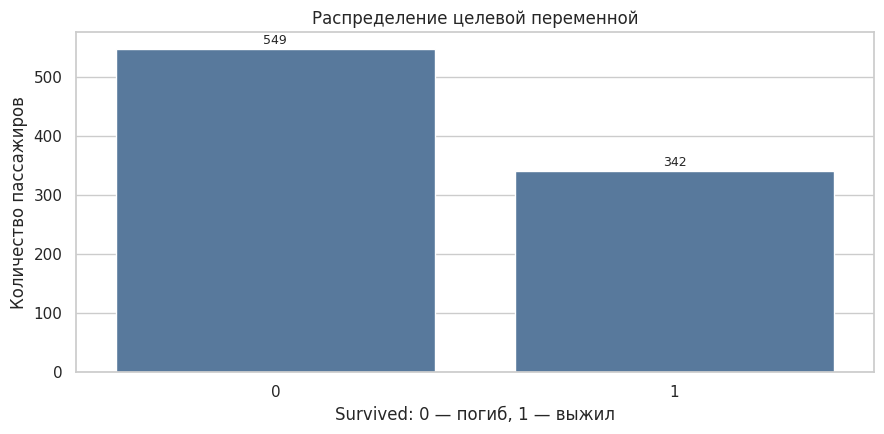

In [4]:
train, test = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["Survived"], random_state=RANDOM_STATE
)
y_train, y_test = train["Survived"], test["Survived"]

split_report = pd.DataFrame({
    "n": [len(train), len(test)],
    "share": [len(train) / len(df), len(test) / len(df)],
    "survived_share": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_report)

survived_counts = df["Survived"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=survived_counts.index, y=survived_counts.values, color="#4C78A8", ax=ax)
ax.set(title="Распределение целевой переменной", xlabel="Survived: 0 — погиб, 1 — выжил", ylabel="Количество пассажиров")
for i, value in enumerate(survived_counts.values):
    ax.text(i, value + survived_counts.max() * 0.015, str(value), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Вывод.** Выжили 342 пассажира (38.4%), погибли 549 (61.6%). Поэтому предсказание только самого частого класса даст заметную Accuracy, но не позволит находить выживших. После стратифицированного разбиения получили 712 строк train и 179 строк test с близкими долями классов.

In [5]:
def age_groups(age):
    return pd.cut(age, [0, 12, 18, 35, 60, np.inf], right=False,
                  labels=["0–11", "12–17", "18–34", "35–59", "60+"]).cat.add_categories(["Неизвестен"]).fillna("Неизвестен")

eda = train.assign(AgeGroup=age_groups(train.Age), LogFare=np.log1p(train.Fare))

for column in ["Sex", "Pclass", "AgeGroup"]:
    display(eda.groupby(column, observed=False).Survived.agg(N="size", Доля_выживших="mean"))

display(train.groupby("Survived")[["Age", "Fare"]].median().rename_axis("Survived: медианы"))

,N,Доля_выживших
Sex,,
female,253,0.743
male,459,0.185


,N,Доля_выживших
Pclass,,
1,171,0.649
2,150,0.447
3,391,0.243


,N,Доля_выживших
AgeGroup,,
0–11,54,0.593
12–17,31,0.484
18–34,294,0.364
35–59,178,0.427
60+,18,0.167
Неизвестен,137,0.292


,Age,Fare
Survived: медианы,,
0,28.250,10.500
1,29.000,26.000


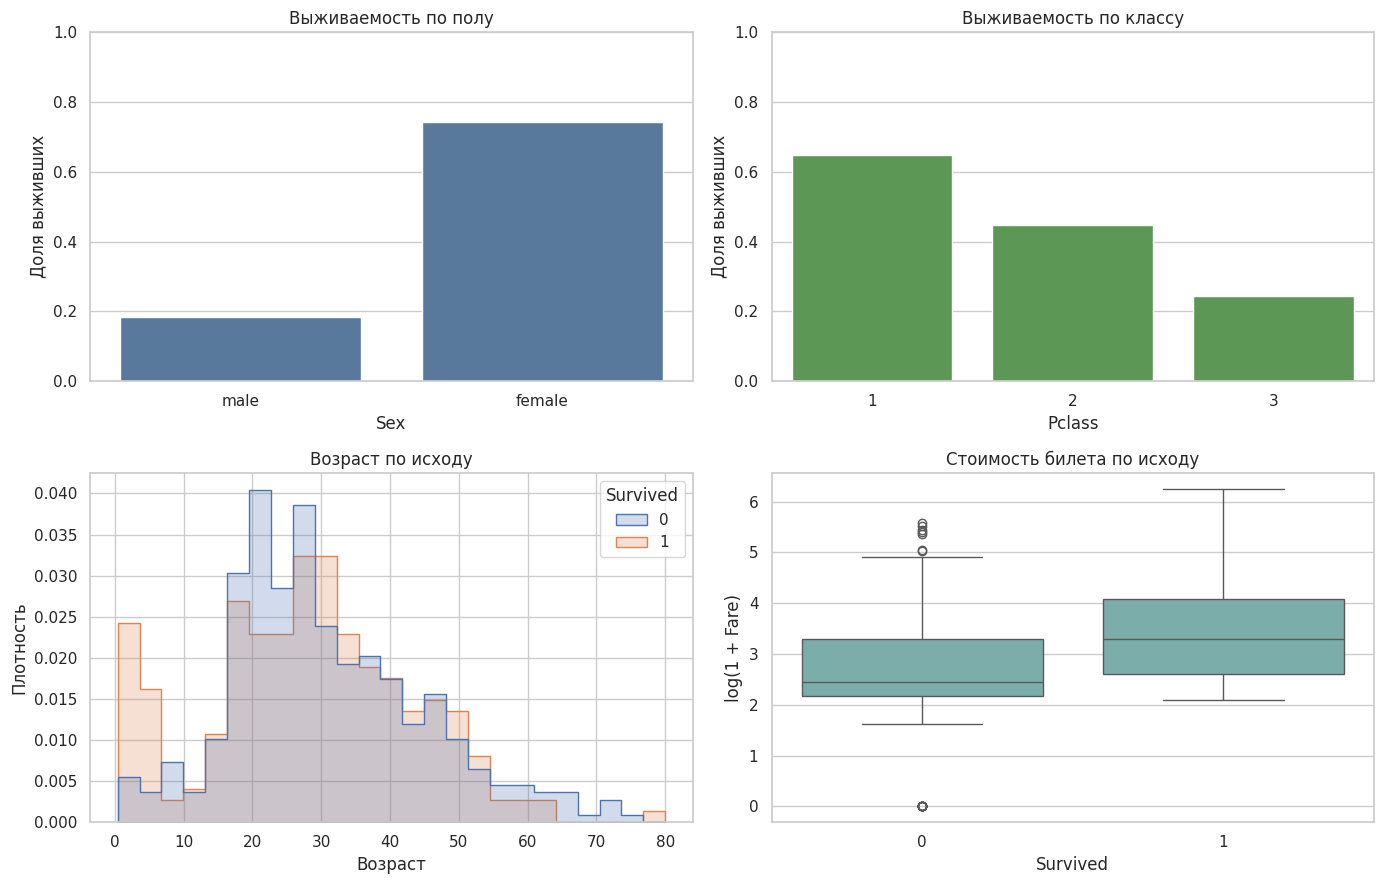

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.barplot(data=eda, x="Sex", y="Survived", errorbar=None, color="#4C78A8", ax=axes[0, 0])
axes[0, 0].set(title="Выживаемость по полу", ylabel="Доля выживших", ylim=(0, 1))
sns.barplot(data=eda, x="Pclass", y="Survived", errorbar=None, color="#54A24B", ax=axes[0, 1])
axes[0, 1].set(title="Выживаемость по классу", ylabel="Доля выживших", ylim=(0, 1))
sns.histplot(data=eda, x="Age", hue="Survived", bins=25, stat="density", common_norm=False, element="step", ax=axes[1, 0])
axes[1, 0].set(title="Возраст по исходу", xlabel="Возраст", ylabel="Плотность")
sns.boxplot(data=eda, x="Survived", y="LogFare", color="#72B7B2", ax=axes[1, 1])
axes[1, 1].set(title="Стоимость билета по исходу", ylabel="log(1 + Fare)")
plt.tight_layout()
plt.show()

**Вывод.** На train выжили 74.3% женщин и 18.5% мужчин; в 1-м классе — 64.9%, в 3-м — 24.3%. У детей до 12 лет доля выживших 59.3% (54 наблюдения), у пассажиров 18–34 лет — 36.4% (294 наблюдения). Медиана Fare у выживших — 26.00, у погибших — 10.50.

Групповые распределения перекрываются: один признак не определяет исход. Это аргумент в пользу многомерных моделей, учитывающих нелинейные зависимости и взаимодействия. `log1p(Fare)` используется только на графике, чтобы длинный хвост цены не скрывал остальные наблюдения.

## 3. Подготовка признаков

`PassengerId` исключаем как уникальный номер. Полные `Name` и `Ticket` имеют высокую кардинальность и могут способствовать запоминанию; `Cabin` дополнительно содержит много пропусков. Сами по себе эти столбцы не являются доказанной утечкой цели.

Из `Name` берём только **Title**: Mr, Mrs, Miss, Master или Rare. Это общие категории, связанные с полом и возрастом, без сохранения имени. **FamilySize = SibSp + Parch + 1** описывает размер сопровождающей семьи. Оба преобразования выполняются по фиксированным правилам без цели и статистик датасета.

Числа заполняем медианой, категории — модой; затем one-hot с `handle_unknown="ignore"`. `Pclass` считаем категорией. Для SVC и KNN масштабируем числа: иначе Fare будет чрезмерно влиять на расстояния. Деревьям масштабирование обычно не нужно, поскольку порядок значений и пороговые разделения сохраняются. Импутация, кодирование и scaling обучаются внутри Pipeline на каждом обучающем фолде.

In [7]:
def make_features(data):
    features = data[["Age", "SibSp", "Parch", "Fare", "Pclass", "Sex", "Embarked"]].copy()
    title = data["Name"].str.extract(r", ([^.]+).", expand=False)
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    features["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    features["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    return features

X_train, X_test = make_features(train), make_features(test)
numeric = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
categorical = ["Pclass", "Sex", "Embarked", "Title"]

display(X_train.head())

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Title,FamilySize
692,NaN,0,0,56.496,3,male,S,Mr,1
481,NaN,0,0,0.000,2,male,S,Mr,1
527,NaN,0,0,221.779,1,male,S,Mr,1
855,18.000,0,1,9.350,3,female,S,Mrs,2
801,31.000,1,1,26.250,2,female,S,Mrs,3


In [8]:
def make_preprocessor(scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical),
    ])

**Вывод.** Используем 9 признаков. Полных идентификаторов и Survived в X нет; Title имеет 5 категорий на train. Пропущенные значения будут заполнены внутри каждого обучающего фолда.

## 4. Метрики и baseline

- **Accuracy** — доля всех верных ответов.
- **Precision** — доля действительно выживших среди предсказанных выживших.
- **Recall** — доля найденных моделью выживших среди всех выживших.
- **F1 = 2 · Precision · Recall / (Precision + Recall)** — баланс Precision и Recall для класса 1. В отличие от одной Accuracy, эта метрика не вознаграждает угадывание только погибших.

Dummy всегда предсказывает наиболее частый класс. Для него и пяти основных моделей используем одинаковые пять фолдов `StratifiedKFold(shuffle=True, random_state=42)` и одни определения метрик. Если положительных прогнозов нет, используем `zero_division=0`. Тестовые результаты считаем вместе после фиксации настроек.

In [9]:
def metrics(actual, predicted):
    return {"Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(actual, predicted, pos_label=1, zero_division=0),
            "Recall": recall_score(actual, predicted, pos_label=1, zero_division=0),
            "F1": f1_score(actual, predicted, pos_label=1, zero_division=0)}

cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
f1_scorer = make_scorer(f1_score, pos_label=1, zero_division=0)

def cv_metrics(predicted):
    return pd.DataFrame([metrics(y_train.iloc[valid], predicted[valid]) for _, valid in cv])

baseline = Pipeline([("preprocess", make_preprocessor()), ("model", DummyClassifier(strategy="most_frequent"))])
baseline_oof = cross_val_predict(baseline, X_train, y_train, cv=cv, n_jobs=1)
baseline.fit(X_train, y_train)
models = {"Dummy": baseline}
thresholds = {}
baseline_scores = cv_metrics(baseline_oof)
cv_rows = [{"Модель": "Dummy", **{f"CV {name}": value for name, value in baseline_scores.mean().items()},
            "CV F1 std": baseline_scores.F1.std(ddof=0), "Порог": np.nan}]
display(baseline_scores.mean().rename("Dummy: CV").to_frame().T.round(4))

,Accuracy,Precision,Recall,F1
Dummy: CV,0.617,0.000,0.000,0.000


**Вывод.** Dummy предсказывает класс 0: CV Accuracy=0.617, F1=0.000. Угадывание большинства не позволяет находить выживших, поэтому сравнивать модели только по Accuracy нельзя.

## 5. Обучение моделей без подсматривания в test

- **Decision Tree** строит дерево правил; `max_depth` ограничивает глубину, `min_samples_leaf` — минимальный размер листа.
- **Random Forest** объединяет деревья на bootstrap-выборках со случайным выбором признаков; `n_estimators` задаёт число деревьев.
- **Gradient Boosting** последовательно добавляет деревья, уменьшающие текущую функцию потерь; основные параметры — `learning_rate`, `n_estimators`, `max_depth`.
- **SVC** ищет границу с широким зазором; RBF-ядро даёт нелинейную границу, `C` задаёт штраф за ошибки, `gamma` — локальность границы.
- **KNN** голосует по соседям; `n_neighbors` — их число, `weights` — веса голосов, `p=1/2` — манхэттенское/евклидово расстояние.

Гиперпараметры выбираем по CV F1 на train. Все преобразования встроены в Pipeline и заново обучаются внутри фолдов. `class_weight="balanced"` увеличивает вес менее частого класса.

Для каждой выбранной конфигурации получаем out-of-fold вероятности и по тем же фолдам выбираем порог из 0.30–0.60; при равных F1 сохраняется порядок кандидатов в коде. У SVC включено `probability=True`. Модель выбирается по среднему CV F1 после выбора порога, до тестовых результатов. CV используется для подбора и поэтому не является независимой оценкой качества.

In [10]:
specs = {
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), False, {
        "model__max_depth": [3, 4, 5, 6, None], "model__min_samples_leaf": [1, 3, 8],
        "model__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1), False, {
        "model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 3],
        "model__class_weight": [None, "balanced"]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), False, {
        "model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [1, 2, 3]}),
    "SVC": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE), True, {
        "model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.1], "model__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(), True, {
        "model__n_neighbors": [5, 9, 15, 25], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
}
threshold_grid = [0.50, 0.45, 0.55, 0.40, 0.60, 0.35, 0.30]
best_parameters = {}

In [11]:
for name, (estimator, scale, grid) in specs.items():
    pipeline = Pipeline([("preprocess", make_preprocessor(scale)), ("model", estimator)])
    search = GridSearchCV(pipeline, grid, scoring=f1_scorer, cv=cv, n_jobs=1, refit=True, error_score="raise")
    search.fit(X_train, y_train)
    model = search.best_estimator_
    # Каждая OOF-вероятность получена моделью, не обученной на соответствующей строке.
    oof_probability = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
    threshold_scores = [cv_metrics((oof_probability >= threshold).astype(int)).F1.mean() for threshold in threshold_grid]
    threshold = threshold_grid[int(np.argmax(threshold_scores))]
    scores = cv_metrics((oof_probability >= threshold).astype(int))
    models[name], thresholds[name] = model, threshold
    best_parameters[name] = search.best_params_
    cv_rows.append({"Модель": name, **{f"CV {metric}": value for metric, value in scores.mean().items()},
                    "CV F1 std": scores.F1.std(ddof=0), "Порог": threshold})
    print(name, search.best_params_, "Порог:", threshold)

cv_table = pd.DataFrame(cv_rows).set_index("Модель").sort_values("CV F1", ascending=False, kind="stable")
best_name = cv_table.drop(index="Dummy")["CV F1"].idxmax()
display(cv_table.round(4))

Decision Tree {'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 1} Порог: 0.5


Random Forest {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 3} Порог: 0.4


Gradient Boosting {'model__learning_rate': 0.05, 'model__max_depth': 1, 'model__n_estimators': 200} Порог: 0.55


SVC {'model__C': 3, 'model__class_weight': 'balanced', 'model__gamma': 0.1} Порог: 0.4


KNN {'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'uniform'} Порог: 0.4


,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 std,Порог
Модель,,,,,,
Random Forest,0.827,0.746,0.839,0.789,0.041,0.400
KNN,0.819,0.749,0.802,0.773,0.053,0.400
SVC,0.825,0.779,0.766,0.770,0.035,0.400
Gradient Boosting,0.830,0.810,0.729,0.767,0.037,0.550
Decision Tree,0.829,0.810,0.729,0.763,0.057,0.500
Dummy,0.617,0.000,0.000,0.000,0.000,NaN


**Вывод.** По CV выбрана **Random Forest**: F1=0.7889, разброс по фолдам 0.0413. Параметры, признаки и пороги всех моделей зафиксированы; после тестовой оценки они не изменяются.

## 6. Единая финальная оценка на test

Порог качества проверяем по неокруглённому F1. В confusion matrix строки — истинные классы, столбцы — прогноз: `[[TN, FP], [FN, TP]]`.

**FP:** предсказано выживание, но пассажир погиб. **FN:** предсказана гибель, но пассажир выжил.

In [12]:
def predict(name, features):
    if name == "Dummy":
        return models[name].predict(features)
    return (models[name].predict_proba(features)[:, 1] >= thresholds[name]).astype(int)

predictions = {name: predict(name, X_test) for name in models}
test_table = pd.DataFrame({name: metrics(y_test, pred) for name, pred in predictions.items()}).T.loc[cv_table.index]
test_table["F1 > 0.70"] = test_table.F1 > 0.70
display(test_table.round(4))

,Accuracy,Precision,Recall,F1,F1 > 0.70
Модель,,,,,
Random Forest,0.799,0.704,0.826,0.760,True
KNN,0.810,0.747,0.768,0.757,True
SVC,0.821,0.768,0.768,0.768,True
Gradient Boosting,0.799,0.770,0.681,0.723,True
Decision Tree,0.832,0.800,0.754,0.776,True
Dummy,0.615,0.000,0.000,0.000,False


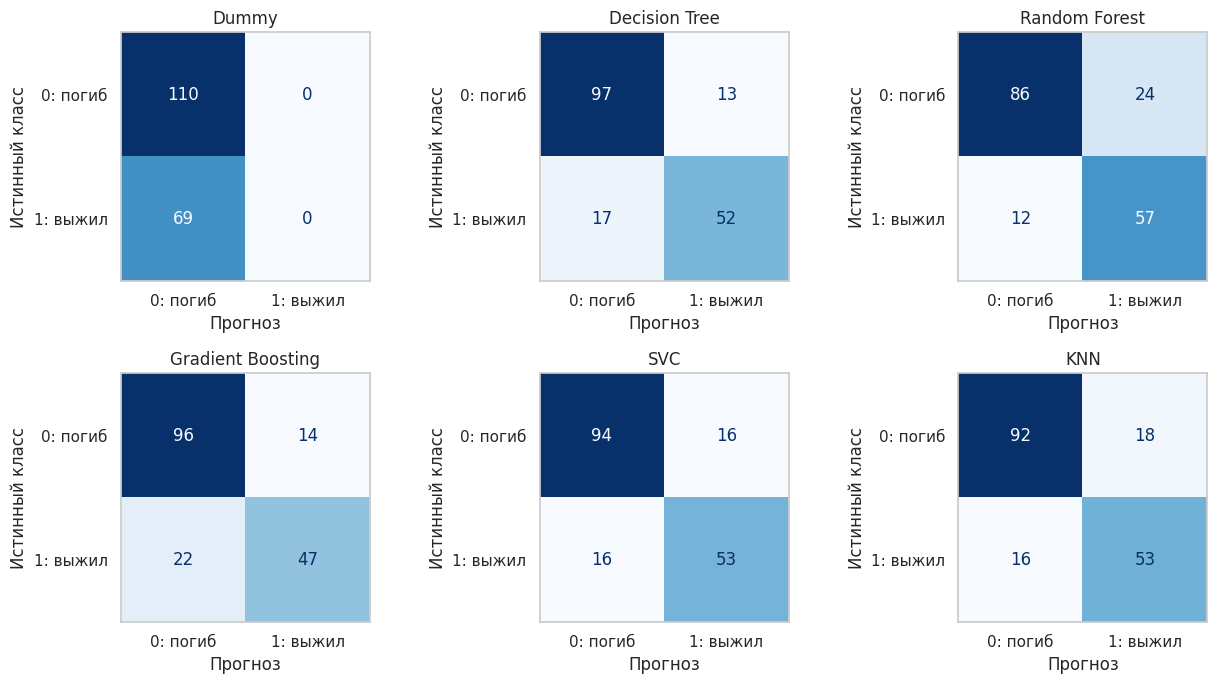

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (name, prediction) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=[0, 1], display_labels=["0: погиб", "1: выжил"],
                                            ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set(title=name, xlabel="Прогноз", ylabel="Истинный класс")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Вывод.** Порог F1 > 0.70 прошли: Random Forest, KNN, SVC, Gradient Boosting, Decision Tree. У Dummy F1=0.000; выбранная по CV модель — Random Forest.

## 7. Проверка переобучения Decision Tree

Сравним качество дерева на train и test. Заметное преимущество на обучающей части может указывать на переобучение.

In [14]:
tree_train = metrics(y_train, predict("Decision Tree", X_train))
tree_comparison = pd.DataFrame({"train": tree_train, "test": test_table.loc["Decision Tree", list(tree_train)].to_dict()}).T.astype(float)
display(tree_comparison.round(4))

,Accuracy,Precision,Recall,F1
train,0.840,0.809,0.762,0.785
test,0.832,0.800,0.754,0.776


**Дерево:** разрыв F1 train−test = +0.0088. Разрыв невелик; явных признаков сильного переобучения по этому сравнению нет. Одного разбиения недостаточно для окончательного вывода.

**Сравнение моделей.** F1 Gradient Boosting=0.7231, Random Forest=0.7600; Precision/Recall: 0.770/0.681 и 0.704/0.826. Лес уменьшает разброс усреднением деревьев, бустинг последовательно уменьшает ошибки. Одиночное дерево менее устойчиво; SVC строит гладкую нелинейную границу, KNN зависит от локальных соседей и масштаба. На различия также влияют параметры и случайность небольшого test.

## 8. Feature importance деревьев

Для дерева, леса и бустинга используем `feature_importances_`. Имена после обработки восстанавливаем через `get_feature_names_out()`. One-hot важности дополнительно суммируем по исходным признакам.

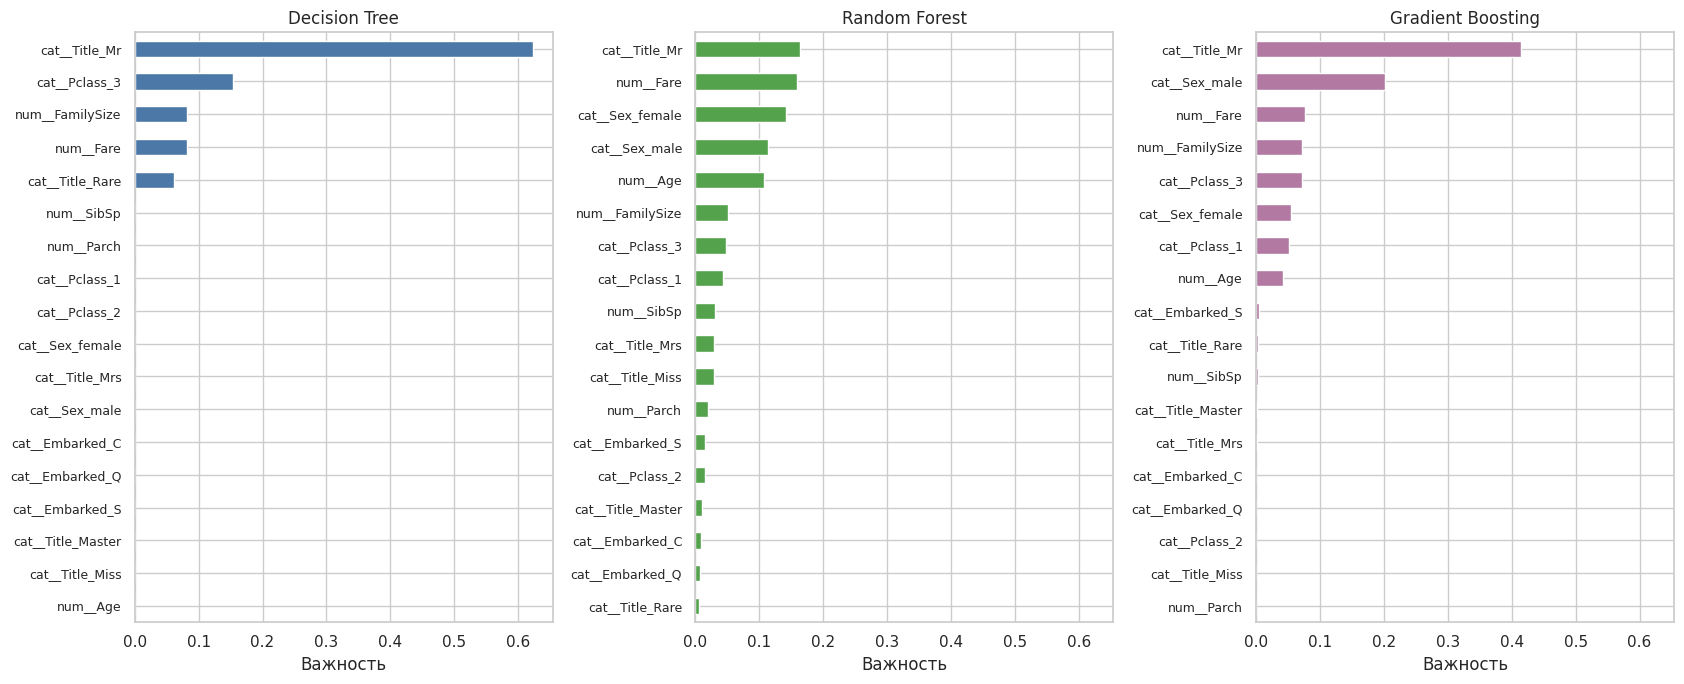

,Decision Tree,Random Forest,Gradient Boosting
Исходный,,,
Age,0.000,0.108,0.042
Embarked,0.000,0.031,0.004
FamilySize,0.082,0.050,0.072
Fare,0.081,0.160,0.077
Parch,0.000,0.020,0.000
Pclass,0.154,0.106,0.124
Sex,0.000,0.255,0.257
SibSp,0.000,0.031,0.003
Title,0.683,0.238,0.420


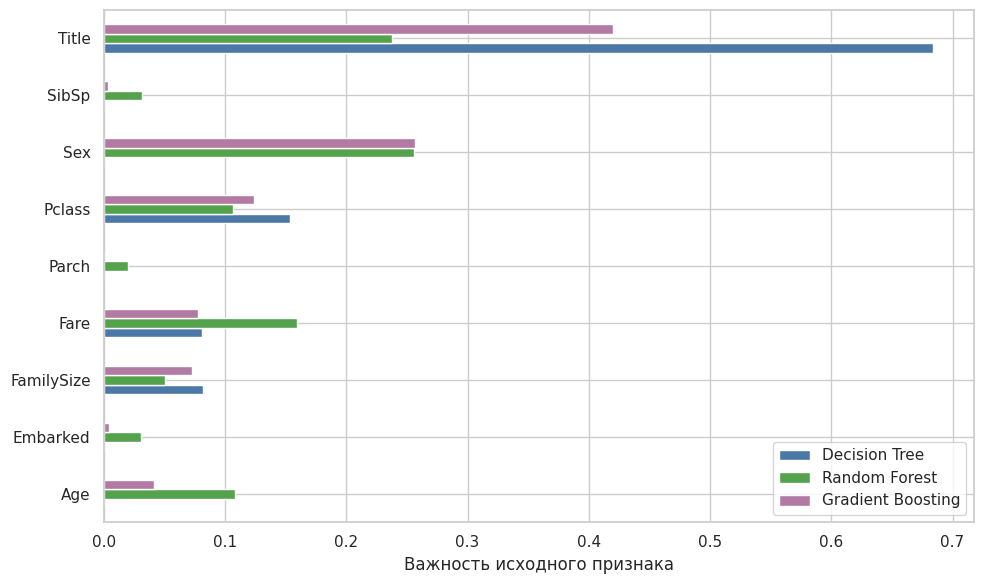

In [15]:
tree_names = ["Decision Tree", "Random Forest", "Gradient Boosting"]
aggregated = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharex=True)
for ax, name, color in zip(axes, tree_names, ["#4C78A8", "#54A24B", "#B279A2"]):
    preprocessor = models[name].named_steps["preprocess"]
    names = preprocessor.get_feature_names_out()
    importance = models[name].named_steps["model"].feature_importances_
    original = list(numeric)
    encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
    for column, categories in zip(categorical, encoder.categories_):
        original.extend([column] * len(categories))
    assert len(names) == len(original) == len(importance)
    table = pd.DataFrame({"Признак": names, "Исходный": original, "Важность": importance})
    table.sort_values("Важность").plot.barh(x="Признак", y="Важность", ax=ax, legend=False, color=color)
    ax.set(title=name, ylabel="", xlabel="Важность")
    ax.tick_params(axis="y", labelsize=9)
    aggregated[name] = table.groupby("Исходный").Важность.sum()
plt.tight_layout()
plt.show()
importance_table = pd.DataFrame(aggregated)
display(importance_table.round(4))
importance_table.plot.barh(figsize=(10, 6), color=["#4C78A8", "#54A24B", "#B279A2"])
plt.xlabel("Важность исходного признака")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Decision Tree:** Title (0.684), Pclass (0.154), FamilySize (0.082)

**Random Forest:** Sex (0.255), Title (0.238), Fare (0.160)

**Gradient Boosting:** Title (0.420), Sex (0.257), Pclass (0.124)

**Сопоставление.** Title обобщает связанные с полом и возрастом сведения, FamilySize — сведения о родственниках. Вместе с Sex, Pclass и Fare это сопоставляется с различиями выживаемости на train. Разные ансамбли могут распределять вклад между связанными признаками по-разному.

Важности отражают снижение критерия в обученных деревьях, а не причинное влияние. Они могут быть смещены в пользу признаков с большим числом разбиений; коррелирующие признаки делят вклад. Наблюдательные данные и эти оценки не доказывают, что изменение признака вызвало бы изменение выживаемости.

## 9. Анализ ошибок лучшей модели

Разберём ошибки Random Forest — модели, выбранной по CV. Посмотрим на FP и FN и доли ошибок по полу, классу билета и возрасту.

In [16]:
errors = test.copy()
errors["Prediction"] = predictions[best_name]
errors["Error"] = errors.Survived != errors.Prediction
errors["FP"] = (errors.Survived == 0) & (errors.Prediction == 1)
errors["FN"] = (errors.Survived == 1) & (errors.Prediction == 0)
errors["AgeGroup"] = age_groups(errors.Age)
tn, fp, fn, tp = confusion_matrix(y_test, predictions[best_name], labels=[0, 1]).ravel()
print(f"{best_name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
error_by_group = {}
for column in ["Sex", "Pclass", "AgeGroup"]:
    group = errors.groupby(column, observed=False).agg(N=("Error", "size"), Ошибок=("Error", "sum"), FP=("FP", "sum"), FN=("FN", "sum"))
    group["Доля ошибок"] = group["Ошибок"] / group.N.replace(0, np.nan)
    error_by_group[column] = group
    display(group.round(4))

Random Forest: TN=86, FP=24, FN=12, TP=57


,N,Ошибок,FP,FN,Доля ошибок
Sex,,,,,
female,61,10,10,0,0.164
male,118,26,14,12,0.220


,N,Ошибок,FP,FN,Доля ошибок
Pclass,,,,,
1,45,18,14,4,0.400
2,34,3,1,2,0.088
3,100,15,9,6,0.150


,N,Ошибок,FP,FN,Доля ошибок
AgeGroup,,,,,
0–11,14,1,1,0,0.071
12–17,14,0,0,0,0.000
18–34,72,14,8,6,0.194
35–59,31,8,7,1,0.258
60+,8,5,3,2,0.625
Неизвестен,40,8,5,3,0.200


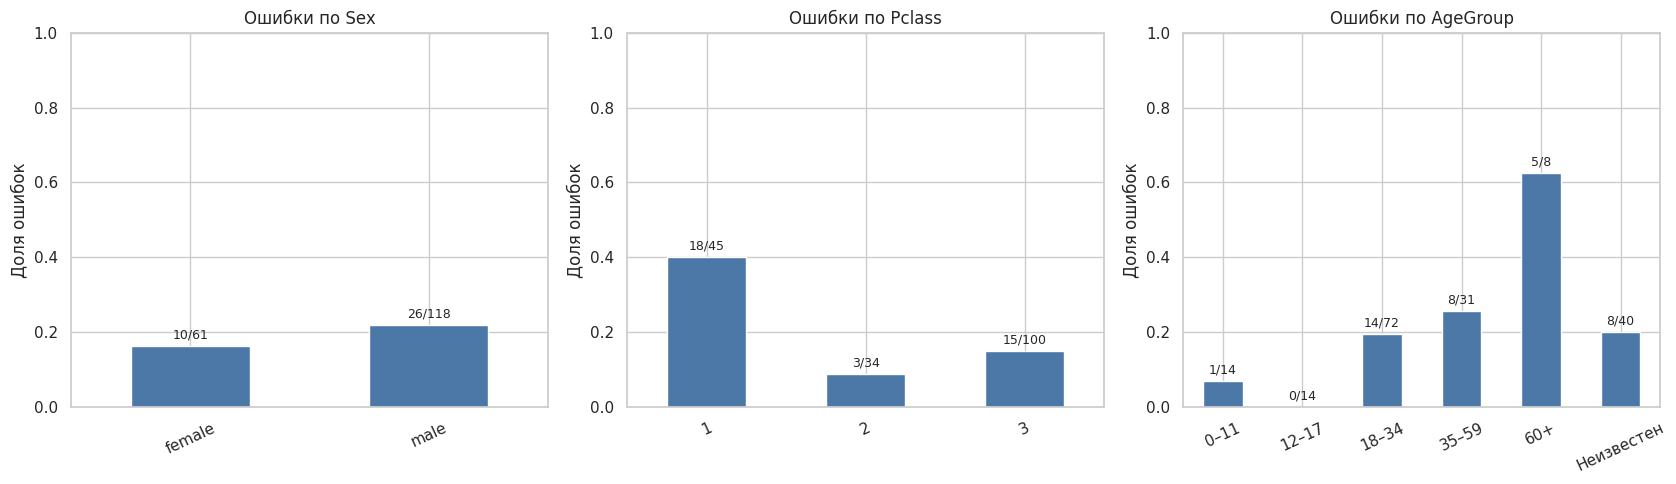

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for column, ax in zip(["Sex", "Pclass", "AgeGroup"], axes):
    group = error_by_group[column]
    group["Доля ошибок"].plot(kind="bar", color="#4C78A8", ax=ax)
    ax.set(title=f"Ошибки по {column}", xlabel="", ylabel="Доля ошибок", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=25)
    for i, (_, row) in enumerate(group.iterrows()):
        ax.text(i, row["Доля ошибок"] + 0.02, f"{int(row['Ошибок'])}/{int(row['N'])}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Разбор ошибок.** У Random Forest 24 FP и 12 FN: модель чаще предсказывает выживание погибшему, чем пропускает выжившего. Доля ошибок у мужчин — 22.0%, у женщин — 16.4%. Среди классов билета она выше в 1-м классе: 18 ошибок из 45 наблюдений (40.0%).

В группе 60+ получено 5 ошибок из 8 (62.5%), однако группа мала: изменение прогноза всего одного пассажира меняет долю на 12.5 процентного пункта. Поэтому высокую долю нельзя считать устойчивым свойством качества модели для всех пожилых пассажиров. Анализ test используется для обсуждения ограничений без повторной настройки.

In [18]:
examples = pd.concat([errors.loc[errors.FP].sort_index().head(2), errors.loc[errors.FN].sort_index().head(2)]).sort_index()
example_features = make_features(examples)
example_table = examples[["PassengerId", "Survived", "Prediction"]].join(example_features)
display(example_table)
assert not {"Survived", "PassengerId", "Name", "Ticket", "Cabin"} & set(X_train.columns)

,PassengerId,Survived,Prediction,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Title,FamilySize
17,18,1,0,NaN,0,0,13.000,2,male,S,Mr,1
23,24,1,0,28.000,0,0,35.500,1,male,S,Mr,1
38,39,0,1,18.000,2,0,18.000,3,female,S,Miss,3
40,41,0,1,40.000,1,0,9.475,3,female,S,Mrs,2


**Пассажир 18:** факт 1, прогноз 0. На train у Title=Mr доля выживших 15.3% (N=412). Общий групповой паттерн мог не сработать для отдельного человека. Пропущенный возраст заменён медианой, что могло скрыть индивидуальные различия.

**Пассажир 24:** факт 1, прогноз 0. На train у Title=Mr доля выживших 15.3% (N=412). Общий групповой паттерн мог не сработать для отдельного человека.

**Пассажир 39:** факт 0, прогноз 1. На train у Title=Miss доля выживших 70.8% (N=144). Общий групповой паттерн мог не сработать для отдельного человека.

**Пассажир 41:** факт 0, прогноз 1. На train у Title=Mrs доля выживших 78.5% (N=107). Общий групповой паттерн мог не сработать для отдельного человека.

**Вывод.** Разобраны 4 ошибочных прогноза; объяснения — гипотезы, а не установленные причины. Цель и полные идентификаторы в модель не входят, Title ограничен общими категориями. У 67 тестовых пассажиров билет встречается и в train: зависимость пассажиров остаётся ограничением разбиения по строкам.

## 10. Итоговый вывод

Выбрана **Random Forest** по максимальному CV F1=0.7889. На test: Accuracy=0.7989, Precision=0.7037, Recall=0.8261, **F1=0.7600**. У Dummy F1=0.0000. **Все пять основных моделей достигли F1 > 0.70.** Ведущие признаки трёх древесных моделей в среднем: Title, Sex, Pclass. Ограничения — малая выборка, пропуски, зависимые пассажиры и неполные сведения об эвакуации. Для leaderboard необходим официальный test.